In [2]:
print("Customer Churn Prediction")


Customer Churn Prediction


In [3]:
import pandas
import numpy
import matplotlib
import seaborn
import sklearn

print("All five libraries are installed!")

All five libraries are installed!


In [4]:
import pandas as pd

df = pd.read_csv("../data/WA_Fn-UseC_-Telco-Customer-Churn.csv")

df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [5]:
df.shape


(7043, 21)

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [7]:
df.describe()


,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [8]:
df["Churn"].value_counts()

Churn
No     5174
Yes    1869
Name: count, dtype: int64

In [9]:
churn_percentage = (df["Churn"].value_counts()["Yes"] / len(df)) * 100

print(churn_percentage)

26.536987079369588


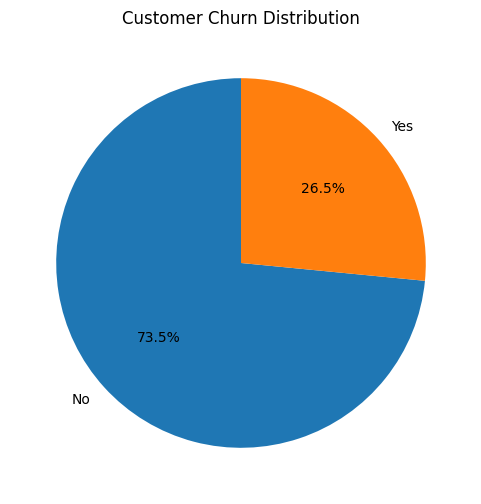

In [10]:
import matplotlib.pyplot as plt

churn_counts = df["Churn"].value_counts()

plt.figure(figsize=(6, 6))
plt.pie(
    churn_counts,
    labels=churn_counts.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Customer Churn Distribution")
plt.show()

In [11]:
pd.crosstab(df["Contract"], df["Churn"])


Churn,No,Yes
Contract,,
Month-to-month,2220,1655
One year,1307,166
Two year,1647,48


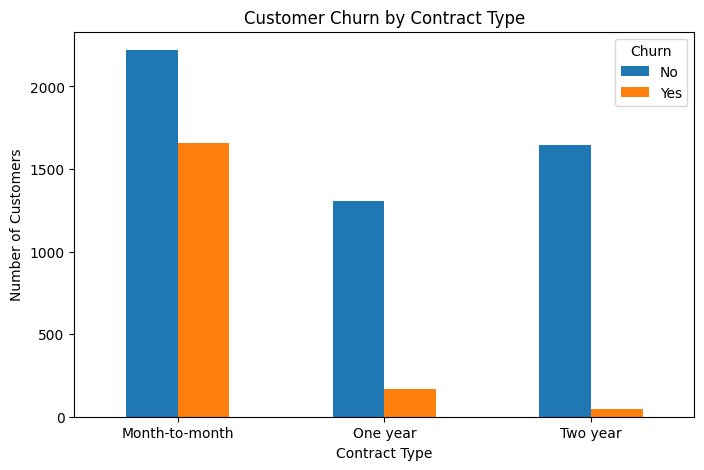

In [12]:
contract_churn = pd.crosstab(df["Contract"], df["Churn"])

contract_churn.plot(kind="bar", figsize=(8, 5))

plt.title("Customer Churn by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)
plt.legend(title="Churn")
plt.show()

In [13]:
df.groupby("Churn")["tenure"].mean()


Churn
No     37.569965
Yes    17.979133
Name: tenure, dtype: float64

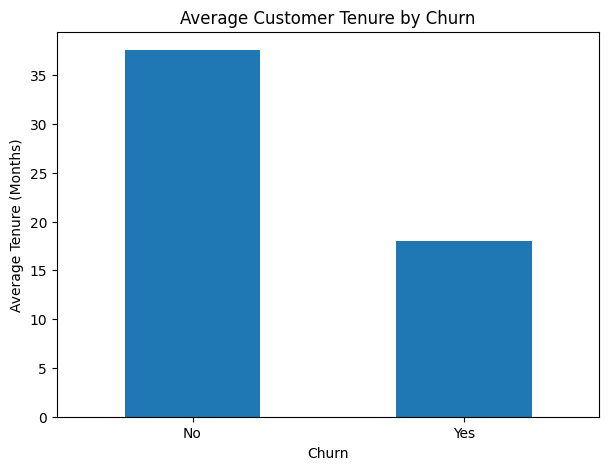

In [14]:
tenure_data = df.groupby("Churn")["tenure"].mean()

tenure_data.plot(kind="bar", figsize=(7, 5))

plt.title("Average Customer Tenure by Churn")
plt.xlabel("Churn")
plt.ylabel("Average Tenure (Months)")
plt.xticks(rotation=0)
plt.show()

In [15]:
df.groupby("Churn")["MonthlyCharges"].mean()

Churn
No     61.265124
Yes    74.441332
Name: MonthlyCharges, dtype: float64

In [16]:
df.groupby("Churn")["MonthlyCharges"].mean()

Churn
No     61.265124
Yes    74.441332
Name: MonthlyCharges, dtype: float64

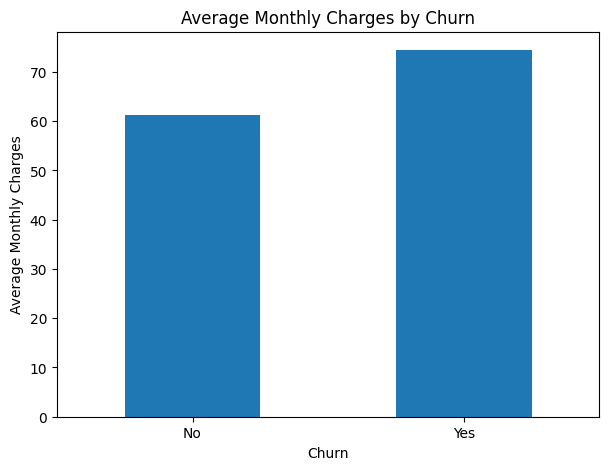

In [17]:
monthly_data = df.groupby("Churn")["MonthlyCharges"].mean()

monthly_data.plot(kind="bar", figsize=(7, 5))

plt.title("Average Monthly Charges by Churn")
plt.xlabel("Churn")
plt.ylabel("Average Monthly Charges")
plt.xticks(rotation=0)
plt.show()

In [18]:
# Check missing values
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [19]:
df["TotalCharges"].value_counts().head()

TotalCharges
20.2     11
         11
19.75     9
19.65     8
19.9      8
Name: count, dtype: int64

In [20]:
df["TotalCharges"].dtype

dtype('O')

In [21]:
(df["TotalCharges"].str.strip() == "").sum()

np.int64(11)

In [22]:
df_clean = df.copy()

In [23]:
df_clean["TotalCharges"] = pd.to_numeric(
    df_clean["TotalCharges"],
    errors="coerce"
    
)

In [24]:
df_clean["TotalCharges"].dtype

dtype('float64')

In [25]:
df_clean["TotalCharges"].isnull().sum()

np.int64(11)

In [26]:
df_clean = df_clean.dropna(subset=["TotalCharges"])


In [27]:
df_clean.shape

(7032, 21)

In [28]:
print(df_clean.shape)
print(df_clean["TotalCharges"].isnull().sum())

(7032, 21)
0


In [29]:
df_clean.duplicated().sum()


np.int64(0)

In [30]:
df_clean.info()

<class 'pandas.core.frame.DataFrame'>
Index: 7032 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7032 non-null   object 
 1   gender            7032 non-null   object 
 2   SeniorCitizen     7032 non-null   int64  
 3   Partner           7032 non-null   object 
 4   Dependents        7032 non-null   object 
 5   tenure            7032 non-null   int64  
 6   PhoneService      7032 non-null   object 
 7   MultipleLines     7032 non-null   object 
 8   InternetService   7032 non-null   object 
 9   OnlineSecurity    7032 non-null   object 
 10  OnlineBackup      7032 non-null   object 
 11  DeviceProtection  7032 non-null   object 
 12  TechSupport       7032 non-null   object 
 13  StreamingTV       7032 non-null   object 
 14  StreamingMovies   7032 non-null   object 
 15  Contract          7032 non-null   object 
 16  PaperlessBilling  7032 non-null   object 
 17  

In [31]:
df_clean = df_clean.drop("customerID", axis=1)

In [32]:
df_clean.shape

(7032, 20)

In [33]:
df_clean.select_dtypes(include="object").columns


Index(['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines',
       'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
       'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract',
       'PaperlessBilling', 'PaymentMethod', 'Churn'],
      dtype='object')

In [34]:
y = df_clean["Churn"]
X = df_clean.drop("Churn", axis=1)

In [35]:
print(X.shape)
print(y.shape)

(7032, 19)
(7032,)


In [36]:
y = y.map({"No": 0, "Yes": 1})

In [37]:
y.value_counts()



Churn
0    5163
1    1869
Name: count, dtype: int64

In [38]:
X = pd.get_dummies(X, drop_first=True, dtype=int)

In [39]:
X.head()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,MultipleLines_Yes,...,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,1,29.85,29.85,0,1,0,0,1,0,...,0,0,0,0,0,0,1,0,1,0
1,0,34,56.95,1889.50,1,0,0,1,0,0,...,0,0,0,0,1,0,0,0,0,1
2,0,2,53.85,108.15,1,0,0,1,0,0,...,0,0,0,0,0,0,1,0,0,1
3,0,45,42.30,1840.75,1,0,0,0,1,0,...,0,0,0,0,1,0,0,0,0,0
4,0,2,70.70,151.65,0,0,0,1,0,0,...,0,0,0,0,0,0,1,0,1,0


In [40]:

X.dtypes.value_counts()

int64      28
float64     2
Name: count, dtype: int64

In [41]:
X.shape


(7032, 30)

In [42]:
X.to_csv("../data/X_processed.csv", index=False)
y.to_csv("../data/y_processed.csv", index=False)

In [43]:
import os

print(os.listdir("../data"))

['feature_importance.csv', 'final_model_comparison.csv', 'model_comparison.csv', 'threshold_comparison.csv', 'WA_Fn-UseC_-Telco-Customer-Churn.csv', 'weighted_model_results.csv', 'X_processed.csv', 'y_processed.csv']


In [44]:
# Day 4 – Feature Engineering

In [45]:
import pandas as pd

X = pd.read_csv("../data/X_processed.csv")
y = pd.read_csv("../data/y_processed.csv")

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (7032, 30)
Target shape: (7032, 1)


In [46]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [47]:
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(5625, 30)
(1407, 30)
(5625, 1)
(1407, 1)


In [48]:
print("Training target distribution:")
print(y_train["Churn"].value_counts(normalize=True) * 100)

print("\nTesting target distribution:")
print(y_test["Churn"].value_counts(normalize=True) * 100)

Training target distribution:
Churn
0    73.422222
1    26.577778
Name: proportion, dtype: float64

Testing target distribution:
Churn
0    73.418621
1    26.581379
Name: proportion, dtype: float64


In [49]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [50]:
print(X_train_scaled.shape)
print(X_test_scaled.shape)

(5625, 30)
(1407, 30)


In [51]:
import pandas as pd

X_train_scaled_df = pd.DataFrame(
    X_train_scaled,
    columns=X_train.columns
)

X_train_scaled_df.head()


,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,MultipleLines_Yes,...,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,-0.439319,1.321816,0.981556,1.659900,0.996274,1.028312,1.529143,0.327542,-0.327542,1.165543,...,-0.522962,-0.797873,-0.522962,-0.799964,-0.515787,1.772603,-1.21303,1.905159,-0.716177,-0.539468
1,-0.439319,-0.267410,-0.971546,-0.562252,0.996274,-0.972468,-0.653961,-3.053048,3.053048,-0.857969,...,-0.522962,-0.797873,-0.522962,-0.799964,-0.515787,-0.564142,-1.21303,-0.524891,1.396302,-0.539468
2,-0.439319,1.444064,0.837066,1.756104,-1.003740,1.028312,-0.653961,0.327542,-0.327542,1.165543,...,-0.522962,-0.797873,-0.522962,-0.799964,-0.515787,1.772603,-1.21303,1.905159,-0.716177,-0.539468
3,-0.439319,-1.204646,0.641092,-0.908326,0.996274,-0.972468,-0.653961,0.327542,-0.327542,-0.857969,...,-0.522962,-0.797873,-0.522962,1.250057,-0.515787,-0.564142,-1.21303,-0.524891,1.396302,-0.539468
4,-0.439319,0.669826,-0.808787,-0.101561,-1.003740,1.028312,-0.653961,-3.053048,3.053048,-0.857969,...,-0.522962,1.253332,-0.522962,-0.799964,-0.515787,-0.564142,-1.21303,-0.524891,-0.716177,-0.539468


In [52]:
print("Mean:", X_train_scaled.mean())
print("Standard deviation:", X_train_scaled.std())

Mean: -1.8021469090685802e-17
Standard deviation: 1.0


In [53]:
#Logistic Regression

In [54]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=1000, random_state=42)

model.fit(X_train_scaled, y_train.values.ravel())

LogisticRegression(max_iter=1000, random_state=42)

In [55]:
y_pred = model.predict(X_test_scaled)

In [56]:
print("Actual values:")
print(y_test.values.ravel()[:10])

print("Predicted values:")
print(y_pred[:10])

Actual values:
[0 0 0 1 0 1 0 0 1 0]
Predicted values:
[0 1 0 0 0 0 0 0 1 0]


In [57]:
y_pred = model.predict(X_test_scaled)
print(y_pred[:10])

[0 1 0 0 0 0 0 0 1 0]


In [58]:
print("Actual values:")
print(y_test.values.ravel()[:10])

print("Predicted values:")
print(y_pred[:10])

Actual values:
[0 0 0 1 0 1 0 0 1 0]
Predicted values:
[0 1 0 0 0 0 0 0 1 0]


In [59]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test.values.ravel(), y_pred)

print("Model Accuracy:", accuracy * 100, "%")


Model Accuracy: 80.38379530916845 %


In [60]:
print("Model: Logistic Regression")
print("Accuracy:", round(accuracy * 100, 2), "%")

Model: Logistic Regression
Accuracy: 80.38 %


In [61]:
from sklearn.tree import DecisionTreeClassifier

dt_model = DecisionTreeClassifier(
    random_state=42
)

In [62]:
dt_model.fit(X_train_scaled, y_train.values.ravel())

DecisionTreeClassifier(random_state=42)

In [63]:
dt_pred = dt_model.predict(X_test_scaled)

print(dt_pred[:10])

[0 1 0 0 0 1 0 0 1 0]


In [64]:
from sklearn.metrics import accuracy_score

dt_accuracy = accuracy_score(
    y_test.values.ravel(),
    dt_pred
)

print("Decision Tree Accuracy:", dt_accuracy * 100, "%")

Decision Tree Accuracy: 71.64179104477611 %


In [65]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

In [66]:
rf_model.fit(X_train_scaled, y_train.values.ravel())


RandomForestClassifier(random_state=42)

In [67]:
rf_pred = rf_model.predict(X_test_scaled)

print(rf_pred[:10])

[0 1 0 0 0 0 0 0 1 0]


In [68]:
rf_accuracy = accuracy_score(
    y_test.values.ravel(),
    rf_pred
)

print("Random Forest Accuracy:", rf_accuracy * 100, "%")

Random Forest Accuracy: 78.82018479033405 %


In [69]:
results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest"
    ],
    "Accuracy": [
        accuracy,
        dt_accuracy,
        rf_accuracy
    ]
})

results["Accuracy"] = results["Accuracy"] * 100

results

,Model,Accuracy
0,Logistic Regression,80.383795
1,Decision Tree,71.641791
2,Random Forest,78.820185


In [70]:
results.to_csv(
    "../data/model_comparison.csv",
    index=False
)

In [71]:
import os
print(os.listdir("../data"))

['feature_importance.csv', 'final_model_comparison.csv', 'model_comparison.csv', 'threshold_comparison.csv', 'WA_Fn-UseC_-Telco-Customer-Churn.csv', 'weighted_model_results.csv', 'X_processed.csv', 'y_processed.csv']


In [72]:
from sklearn.metrics import confusion_matrix

cm_lr = confusion_matrix(
    y_test.values.ravel(),
    y_pred
)

print(cm_lr)


[[916 117]
 [159 215]]


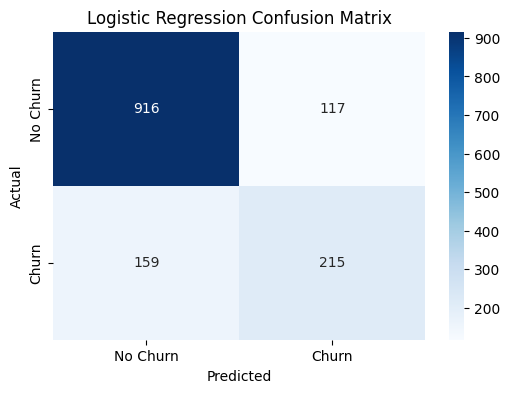

In [73]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm_lr,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Churn", "Churn"],
    yticklabels=["No Churn", "Churn"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Logistic Regression Confusion Matrix")

plt.show()

In [74]:
from sklearn.metrics import classification_report

print(classification_report(
    y_test.values.ravel(),
    y_pred,
    target_names=["No Churn", "Churn"]
))

              precision    recall  f1-score   support

    No Churn       0.85      0.89      0.87      1033
       Churn       0.65      0.57      0.61       374

    accuracy                           0.80      1407
   macro avg       0.75      0.73      0.74      1407
weighted avg       0.80      0.80      0.80      1407



In [75]:
from sklearn.metrics import classification_report

print("DECISION TREE")
print(classification_report(
    y_test.values.ravel(),
    dt_pred,
    target_names=["No Churn", "Churn"]
))

print("RANDOM FOREST")
print(classification_report(
    y_test.values.ravel(),
    rf_pred,
    target_names=["No Churn", "Churn"]
))

DECISION TREE
              precision    recall  f1-score   support

    No Churn       0.81      0.81      0.81      1033
       Churn       0.47      0.46      0.46       374

    accuracy                           0.72      1407
   macro avg       0.64      0.63      0.64      1407
weighted avg       0.72      0.72      0.72      1407

RANDOM FOREST
              precision    recall  f1-score   support

    No Churn       0.83      0.89      0.86      1033
       Churn       0.62      0.51      0.56       374

    accuracy                           0.79      1407
   macro avg       0.73      0.70      0.71      1407
weighted avg       0.78      0.79      0.78      1407



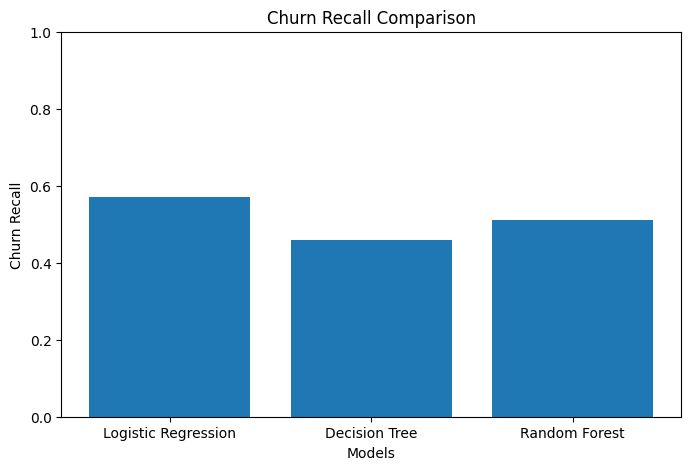

In [76]:
recall_values = [0.57, 0.46, 0.51]

model_names = [
    "Logistic Regression",
    "Decision Tree",
    "Random Forest"
]

plt.figure(figsize=(8, 5))

plt.bar(model_names, recall_values)

plt.ylabel("Churn Recall")
plt.xlabel("Models")
plt.title("Churn Recall Comparison")
plt.ylim(0, 1)

plt.show()

In [77]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

models = {
    "Logistic Regression": y_pred,
    "Decision Tree": dt_pred,
    "Random Forest": rf_pred
}

comparison = []

for name, predictions in models.items():
    comparison.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test.values.ravel(), predictions),
        "Precision": precision_score(y_test.values.ravel(), predictions),
        "Recall": recall_score(y_test.values.ravel(), predictions),
        "F1 Score": f1_score(y_test.values.ravel(), predictions)
    })

comparison_df = pd.DataFrame(comparison)

comparison_df


,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.803838,0.647590,0.574866,0.609065
1,Decision Tree,0.716418,0.466125,0.459893,0.462988
2,Random Forest,0.788202,0.623377,0.513369,0.563050


In [78]:
y_prob = model.predict_proba(X_test_scaled)[:, 1]

y_pred_03 = (y_prob >= 0.3).astype(int)

In [79]:
from sklearn.metrics import classification_report

print(classification_report(
    y_test.values.ravel(),
    y_pred_03,
    target_names=["No Churn", "Churn"]
))

              precision    recall  f1-score   support

    No Churn       0.89      0.74      0.81      1033
       Churn       0.51      0.76      0.61       374

    accuracy                           0.74      1407
   macro avg       0.70      0.75      0.71      1407
weighted avg       0.79      0.74      0.76      1407



In [80]:
threshold_results = pd.DataFrame({
    "Threshold": [0.5, 0.3],
    "Accuracy": [accuracy, accuracy_score(y_test.values.ravel(), y_pred_03)],
    "Precision": [
        precision_score(y_test.values.ravel(), y_pred),
        precision_score(y_test.values.ravel(), y_pred_03)
    ],
    "Recall": [
        recall_score(y_test.values.ravel(), y_pred),
        recall_score(y_test.values.ravel(), y_pred_03)
    ],
    "F1 Score": [
        f1_score(y_test.values.ravel(), y_pred),
        f1_score(y_test.values.ravel(), y_pred_03)
    ]
})

threshold_results

,Threshold,Accuracy,Precision,Recall,F1 Score
0,0.5,0.803838,0.647590,0.574866,0.609065
1,0.3,0.743426,0.511712,0.759358,0.611410


In [81]:

threshold_results.to_csv(
    "../data/threshold_comparison.csv",
    index=False
)

In [82]:
import os
print(os.listdir("../data"))

['feature_importance.csv', 'final_model_comparison.csv', 'model_comparison.csv', 'threshold_comparison.csv', 'WA_Fn-UseC_-Telco-Customer-Churn.csv', 'weighted_model_results.csv', 'X_processed.csv', 'y_processed.csv']


In [83]:
#Improving the Model
threshold_results.to_csv("../data/threshold_comparison.csv", index=False)


In [84]:
import os

print(os.listdir("../data"))

['feature_importance.csv', 'final_model_comparison.csv', 'model_comparison.csv', 'threshold_comparison.csv', 'WA_Fn-UseC_-Telco-Customer-Churn.csv', 'weighted_model_results.csv', 'X_processed.csv', 'y_processed.csv']


In [85]:
from sklearn.linear_model import LogisticRegression

weighted_model = LogisticRegression(
    max_iter=1000,
    random_state=42,
    class_weight="balanced"
)

weighted_model.fit(X_train_scaled, y_train.values.ravel())

LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)

In [86]:
weighted_pred = weighted_model.predict(X_test_scaled)

print(weighted_pred[:10])

[0 1 0 0 0 1 0 0 1 0]


In [87]:
from sklearn.metrics import classification_report

print(classification_report(
    y_test.values.ravel(),
    weighted_pred,
    target_names=["No Churn", "Churn"]
))

              precision    recall  f1-score   support

    No Churn       0.91      0.70      0.79      1033
       Churn       0.49      0.80      0.61       374

    accuracy                           0.73      1407
   macro avg       0.70      0.75      0.70      1407
weighted avg       0.79      0.73      0.74      1407



In [88]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

weighted_results = pd.DataFrame([{
    "Model": "Weighted Logistic Regression",
    "Accuracy": accuracy_score(y_test.values.ravel(), weighted_pred),
    "Precision": precision_score(y_test.values.ravel(), weighted_pred),
    "Recall": recall_score(y_test.values.ravel(), weighted_pred),
    "F1 Score": f1_score(y_test.values.ravel(), weighted_pred)
}])

weighted_results

,Model,Accuracy,Precision,Recall,F1 Score
0,Weighted Logistic Regression,0.726368,0.490939,0.796791,0.607543


In [89]:
weighted_results.to_csv(
    "../data/weighted_model_results.csv",
    index=False
)

In [90]:
import os
print(os.listdir("../data"))

['feature_importance.csv', 'final_model_comparison.csv', 'model_comparison.csv', 'threshold_comparison.csv', 'WA_Fn-UseC_-Telco-Customer-Churn.csv', 'weighted_model_results.csv', 'X_processed.csv', 'y_processed.csv']


In [91]:
final_comparison = pd.DataFrame({
    "Approach": [
        "Logistic Regression (0.5)",
        "Logistic Regression (0.3)",
        "Decision Tree",
        "Random Forest",
        "Weighted Logistic Regression"
    ],
    "Accuracy": [
        accuracy_score(y_test.values.ravel(), y_pred),
        accuracy_score(y_test.values.ravel(), y_pred_03),
        accuracy_score(y_test.values.ravel(), dt_pred),
        accuracy_score(y_test.values.ravel(), rf_pred),
        accuracy_score(y_test.values.ravel(), weighted_pred)
    ],
    "Precision": [
        precision_score(y_test.values.ravel(), y_pred),
        precision_score(y_test.values.ravel(), y_pred_03),
        precision_score(y_test.values.ravel(), dt_pred),
        precision_score(y_test.values.ravel(), rf_pred),
        precision_score(y_test.values.ravel(), weighted_pred)
    ],
    "Recall": [
        recall_score(y_test.values.ravel(), y_pred),
        recall_score(y_test.values.ravel(), y_pred_03),
        recall_score(y_test.values.ravel(), dt_pred),
        recall_score(y_test.values.ravel(), rf_pred),
        recall_score(y_test.values.ravel(), weighted_pred)
    ],
    "F1 Score": [
        f1_score(y_test.values.ravel(), y_pred),
        f1_score(y_test.values.ravel(), y_pred_03),
        f1_score(y_test.values.ravel(), dt_pred),
        f1_score(y_test.values.ravel(), rf_pred),
        f1_score(y_test.values.ravel(), weighted_pred)
    ]
})

final_comparison.round(4)

,Approach,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression (0.5),0.8038,0.6476,0.5749,0.6091
1,Logistic Regression (0.3),0.7434,0.5117,0.7594,0.6114
2,Decision Tree,0.7164,0.4661,0.4599,0.4630
3,Random Forest,0.7882,0.6234,0.5134,0.5630
4,Weighted Logistic Regression,0.7264,0.4909,0.7968,0.6075


In [92]:
final_comparison.to_csv(
    "../data/final_model_comparison.csv",
    index=False
)

In [93]:
import os

print(os.listdir("../data"))

['feature_importance.csv', 'final_model_comparison.csv', 'model_comparison.csv', 'threshold_comparison.csv', 'WA_Fn-UseC_-Telco-Customer-Churn.csv', 'weighted_model_results.csv', 'X_processed.csv', 'y_processed.csv']


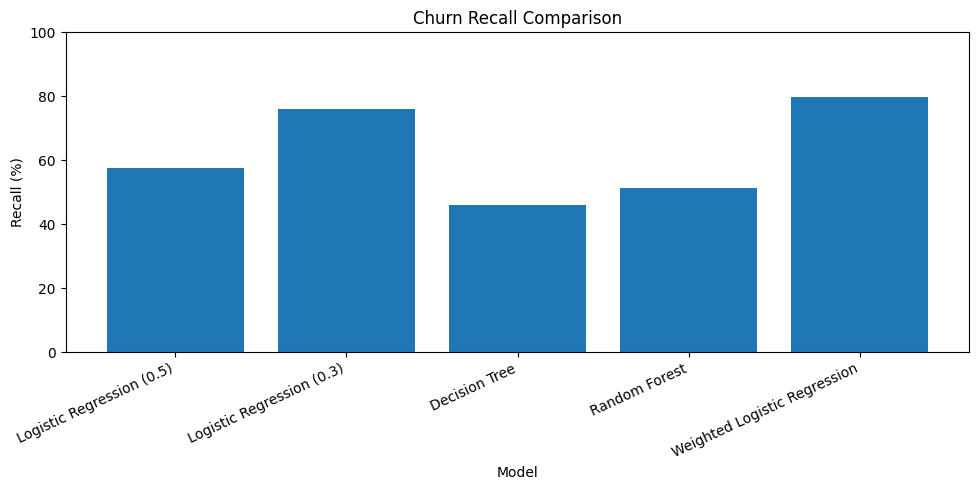

In [94]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.bar(
    final_comparison["Approach"],
    final_comparison["Recall"] * 100
)

plt.title("Churn Recall Comparison")
plt.xlabel("Model")
plt.ylabel("Recall (%)")
plt.xticks(rotation=25, ha="right")
plt.ylim(0, 100)

plt.tight_layout()
plt.show()

In [95]:
#Random Forest model to inspect feature importance.

In [96]:
import pandas as pd
import matplotlib.pyplot as plt

importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf_model.feature_importances_
})

importance = importance.sort_values(
    by="Importance",
    ascending=False
)

importance.head(10)

,Feature,Importance
3,TotalCharges,0.191435
1,tenure,0.171020
2,MonthlyCharges,0.168400
10,InternetService_Fiber optic,0.039481
28,PaymentMethod_Electronic check,0.037416
25,Contract_Two year,0.030529
4,gender_Male,0.029332
13,OnlineSecurity_Yes,0.028157
26,PaperlessBilling_Yes,0.025536
19,TechSupport_Yes,0.024114


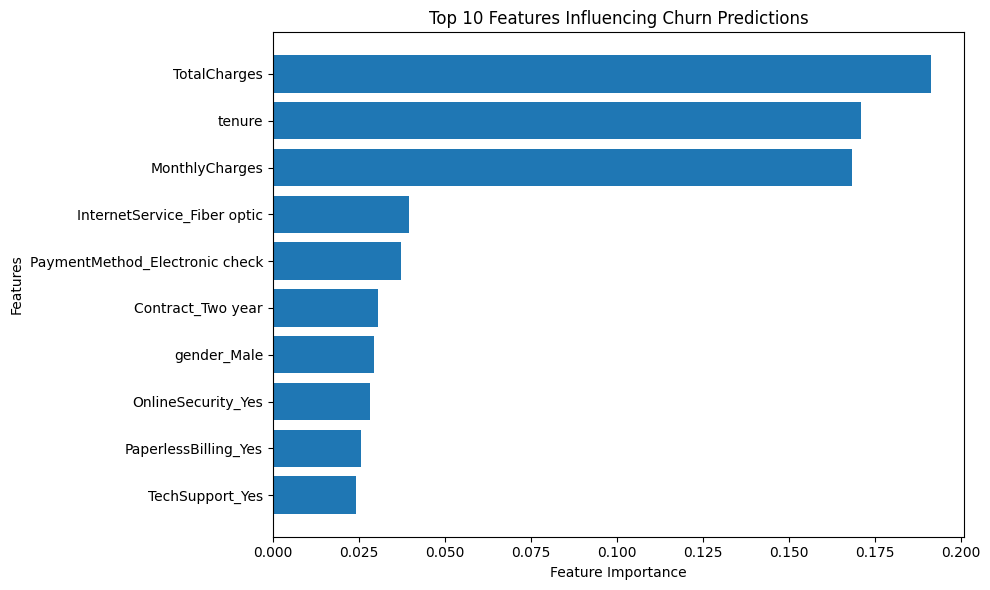

In [97]:
plt.figure(figsize=(10, 6))

top_10 = importance.head(10)

plt.barh(
    top_10["Feature"],
    top_10["Importance"]
)

plt.title("Top 10 Features Influencing Churn Predictions")
plt.xlabel("Feature Importance")
plt.ylabel("Features")
plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

In [98]:
plt.savefig("../visualizations/feature_importance.png",
            bbox_inches="tight")

<Figure size 640x480 with 0 Axes>

In [99]:
importance.to_csv(
    "../data/feature_importance.csv",
    index=False
)

In [100]:
#Build a Customer Churn Prediction System

In [101]:
sample_customer = pd.DataFrame([{
    "gender": "Female",
    "SeniorCitizen": 0,
    "Partner": "No",
    "Dependents": "No",
    "tenure": 12,
    "PhoneService": "Yes",
    "MultipleLines": "No",
    "InternetService": "Fiber optic",
    "OnlineSecurity": "No",
    "OnlineBackup": "No",
    "DeviceProtection": "No",
    "TechSupport": "No",
    "StreamingTV": "Yes",
    "StreamingMovies": "Yes",
    "Contract": "Month-to-month",
    "PaperlessBilling": "Yes",
    "PaymentMethod": "Electronic check",
    "MonthlyCharges": 75.50,
    "TotalCharges": 906.00
}])

sample_customer

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges
0,Female,0,No,No,12,Yes,No,Fiber optic,No,No,No,No,Yes,Yes,Month-to-month,Yes,Electronic check,75.5,906.0


In [102]:
sample_encoded = pd.get_dummies(
    sample_customer,
    drop_first=True,
    dtype=int
)

sample_encoded = sample_encoded.reindex(
    columns=X_train.columns,
    fill_value=0
)

print("Encoded shape:", sample_encoded.shape)

Encoded shape: (1, 30)


In [103]:
sample_scaled = scaler.transform(sample_encoded)

print("Scaled shape:", sample_scaled.shape)

Scaled shape: (1, 30)


In [104]:
prediction = weighted_model.predict(sample_scaled)

if prediction[0] == 1:
    print("Prediction: Customer is likely to CHURN")
else:
    print("Prediction: Customer is likely to STAY")

Prediction: Customer is likely to STAY


In [105]:
churn_probability = weighted_model.predict_proba(sample_scaled)[0][1]

print("Churn Probability:", round(churn_probability * 100, 2), "%")


Churn Probability: 29.53 %


In [106]:
#Let's change the sample customer to have a longer-term contract and longer tenure
sample_customer = pd.DataFrame([{
    "gender": "Female",
    "SeniorCitizen": 0,
    "Partner": "No",
    "Dependents": "No",
    "tenure": 48,
    "PhoneService": "Yes",
    "MultipleLines": "No",
    "InternetService": "Fiber optic",
    "OnlineSecurity": "No",
    "OnlineBackup": "No",
    "DeviceProtection": "No",
    "TechSupport": "No",
    "StreamingTV": "Yes",
    "StreamingMovies": "Yes",
    "Contract": "Two year",
    "PaperlessBilling": "Yes",
    "PaymentMethod": "Electronic check",
    "MonthlyCharges": 65.00,
    "TotalCharges": 3120.00
}])

sample_customer


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges
0,Female,0,No,No,48,Yes,No,Fiber optic,No,No,No,No,Yes,Yes,Two year,Yes,Electronic check,65.0,3120.0


In [107]:
sample_encoded = pd.get_dummies(
    sample_customer, drop_first=True, dtype=int
)

sample_encoded = sample_encoded.reindex(
    columns=X_train.columns, fill_value=0
)

In [108]:
sample_scaled = scaler.transform(sample_encoded)

In [109]:
prediction = weighted_model.predict(sample_scaled)

churn_probability = weighted_model.predict_proba(sample_scaled)[0][1]

print("Prediction:", "CHURN" if prediction[0] == 1 else "STAY")
print("Churn Probability:", round(churn_probability * 100, 2), "%")



Prediction: STAY
Churn Probability: 14.26 %


In [110]:
import os

for folder, subfolders, files in os.walk(".."):
    print(folder)
    for file in files:
        print("   ", file)

..
    New Text Document.txt
..\data
    feature_importance.csv
    final_model_comparison.csv
    model_comparison.csv
    threshold_comparison.csv
    WA_Fn-UseC_-Telco-Customer-Churn.csv
    weighted_model_results.csv
    X_processed.csv
    y_processed.csv
..\models
..\notebooks
    Customer_Churn_Prediction.ipynb
    desktop.ini
..\notebooks\.ipynb_checkpoints
    Customer_Churn_Prediction-checkpoint.ipynb
..\PROJECT_PROGRESS.md
..\src
..\visualizations
    feature_importance.png
